In [18]:
import torch
from torchvision import datasets
from torchvision.transforms import ToTensor
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pathlib
import cv2
import matplotlib.pyplot as plt

In [19]:
pathToModels = pathlib.Path("models")
pathToData = pathlib.Path("data")
BATCH_SIZE = 64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [20]:
trainDataset= datasets.MNIST(root=pathToData, train=True, download=True, transform=ToTensor())
testDataset= datasets.MNIST(root=pathToData, train=False, download=True, transform=ToTensor())
trainLoader = torch.utils.data.DataLoader(trainDataset, batch_size=BATCH_SIZE, shuffle=True)
testLoader = torch.utils.data.DataLoader(testDataset, batch_size=BATCH_SIZE, shuffle=False)

In [21]:
trainDataset[0][0].shape

torch.Size([1, 28, 28])

In [22]:
image = trainDataset[0][0].detach().cpu().numpy().squeeze()
image.shape, type(image), image.dtype, image.min(), image.max()

((28, 28), numpy.ndarray, dtype('float32'), np.float32(0.0), np.float32(1.0))

In [23]:
image = (image * 255).astype(np.uint8)  # Konwersja do formatu uint8
cv2.imwrite('random.jpg', image)

True

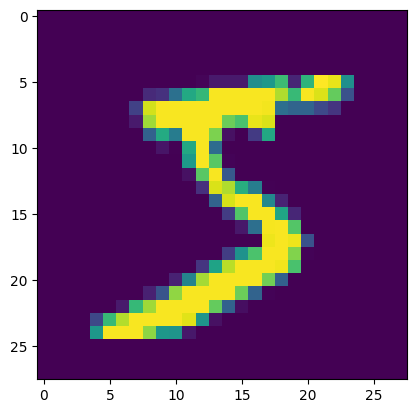

In [24]:
plt.imshow(image)

In [25]:
cv2.imwrite('random.jpg', image)

True

In [26]:
len(trainDataset), len(testDataset)

(60000, 10000)

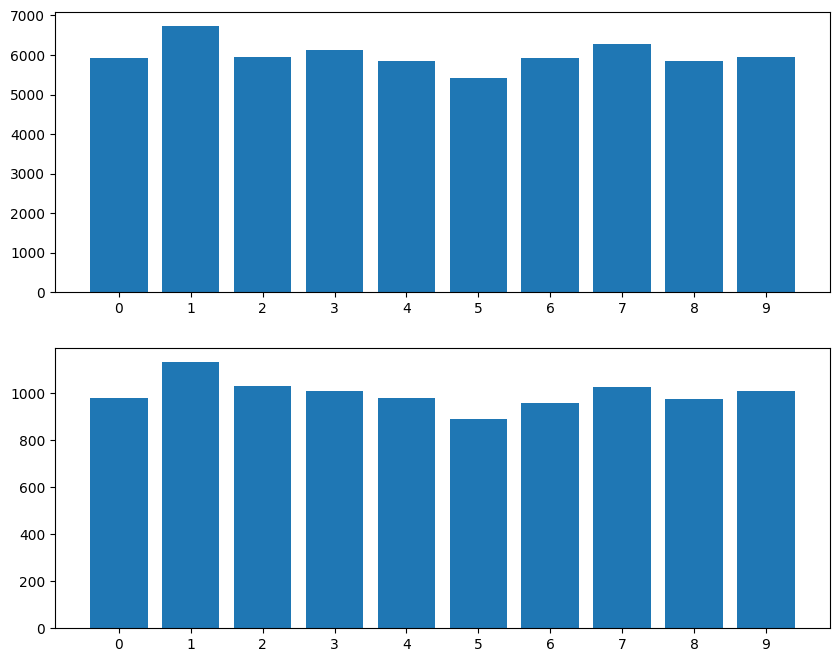

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(10, 8)) 

trainCounts = np.bincount([y for _, y in trainDataset])
axs[0].bar(range(len(trainCounts)), trainCounts)
axs[0].set_xticks(range(len(trainCounts)))

testCounts = np.bincount([y for _, y in testDataset])
axs[1].bar(range(len(testCounts)), testCounts)
axs[1].set_xticks(range(len(testCounts)))

plt.show()

In [28]:
from models.mnist.model import mnistModel

In [29]:
from utils import *

In [30]:
model = mnistModel()

In [31]:
from cam.gradcam import gradcam

In [32]:
from models.mnist.model import loadModel

In [33]:
model = mnistModel()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
model = train(model, trainLoader, testLoader, optimizer, criterion, DEVICE, 3, 'mnist')

Epoch 1/3 - Train Loss: 0.0041, Train Accuracy: 0.9182 - Test Loss: 0.0008, Test Accuracy: 0.9844
Epoch 2/3 - Train Loss: 0.0014, Train Accuracy: 0.9725 - Test Loss: 0.0005, Test Accuracy: 0.9871
Epoch 3/3 - Train Loss: 0.0011, Train Accuracy: 0.9782 - Test Loss: 0.0005, Test Accuracy: 0.9907


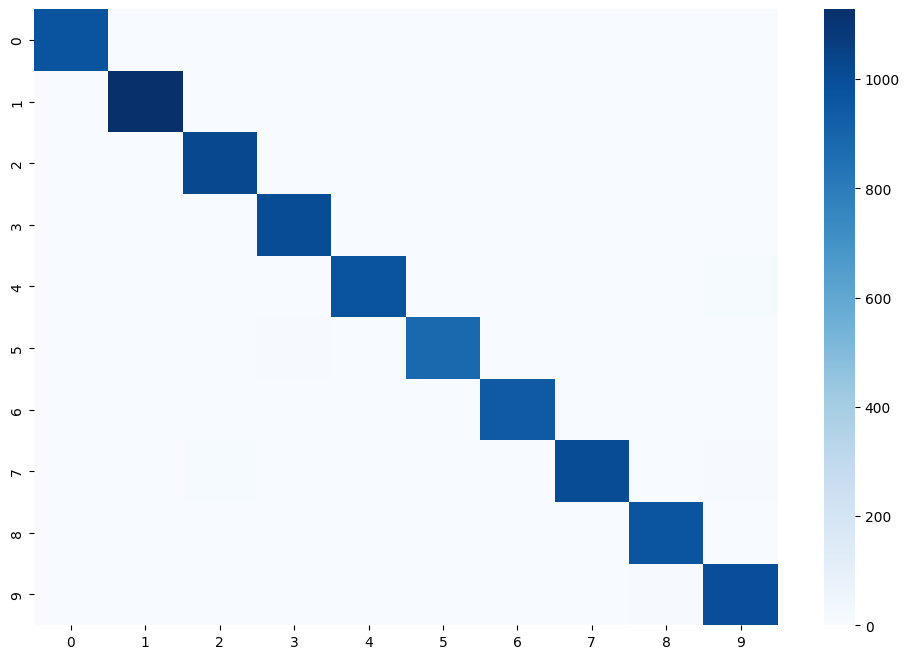

In [34]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true = []
y_pred = []
model.eval()
with torch.no_grad():
    for images, labels in testLoader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, cmap='Blues')
    
plt.show()